# Deep Learning sur données tabulaires, images et texte

## Objectif
Comparer trois architectures adaptées à trois types de données :
- un réseau dense pour les données tabulaires ;
- un CNN pour les images ;
- un réseau récurrent pour le texte.

Pour chaque expérience, les données sont séparées avant tout
prétraitement afin d’éviter les fuites de données.

In [1]:
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow :", tf.__version__)
print("Environnement prêt")

TensorFlow : 2.21.0
Environnement prêt


# 1. Classification sur données tabulaires : Titanic

## Objectif

Prédire si un passager a survécu à partir de caractéristiques
personnelles et liées au voyage.

Un réseau dense, ou MLP, convient car chaque passager est représenté
par une ligne contenant plusieurs variables numériques et catégorielles.

In [2]:
titanic = sns.load_dataset("titanic")

colonnes = [
    "survived",
    "pclass",
    "sex",
    "age",
    "sibsp",
    "parch",
    "fare",
    "embarked",
]

df = titanic[colonnes].copy()

print("Dimensions :", df.shape)
df.head()

Dimensions : (891, 8)


,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [3]:
print("Valeurs manquantes :")
display(df.isna().sum())

print("Répartition de la cible :")
display(df["survived"].value_counts(normalize=True))

Valeurs manquantes :


survived      0
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
dtype: int64

Répartition de la cible :


survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

In [4]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="survived")
y = df["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y,
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train,
)

print("Entraînement :", X_train.shape)
print("Validation    :", X_val.shape)
print("Test          :", X_test.shape)

Entraînement : (569, 7)
Validation    : (143, 7)
Test          : (179, 7)


## Prétraitement des données

Les variables numériques et catégorielles nécessitent des traitements
différents.

### Variables numériques

- Les valeurs manquantes sont remplacées par la médiane.
- Les valeurs sont standardisées pour faciliter l’entraînement du réseau.

### Variables catégorielles

- Les valeurs manquantes sont remplacées par la modalité la plus fréquente.
- Chaque catégorie est transformée en colonne binaire avec un encodage one-hot.

La classe du billet `pclass` est traitée comme une catégorie. Le
préprocesseur est ajusté uniquement sur l’ensemble d’entraînement.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

colonnes_numeriques = [
    "age",
    "sibsp",
    "parch",
    "fare",
]

colonnes_categorielles = [
    "pclass",
    "sex",
    "embarked",
]

pipeline_numerique = Pipeline(
    steps=[
        ("imputation", SimpleImputer(strategy="median")),
        ("normalisation", StandardScaler()),
    ]
)

pipeline_categoriel = Pipeline(
    steps=[
        ("imputation", SimpleImputer(strategy="most_frequent")),
        (
            "encodage",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
        ),
    ]
)

In [6]:
preprocesseur = ColumnTransformer(
    transformers=[
        (
            "numerique",
            pipeline_numerique,
            colonnes_numeriques,
        ),
        (
            "categoriel",
            pipeline_categoriel,
            colonnes_categorielles,
        ),
    ],
    verbose_feature_names_out=False,
)

In [7]:
X_train_prepare = preprocesseur.fit_transform(X_train)

X_val_prepare = preprocesseur.transform(X_val)
X_test_prepare = preprocesseur.transform(X_test)

In [8]:
X_train_prepare = X_train_prepare.astype("float32")
X_val_prepare = X_val_prepare.astype("float32")
X_test_prepare = X_test_prepare.astype("float32")

y_train_array = y_train.to_numpy(dtype="float32")
y_val_array = y_val.to_numpy(dtype="float32")
y_test_array = y_test.to_numpy(dtype="float32")

In [9]:
noms_variables = preprocesseur.get_feature_names_out()

print("Variables produites :")
print(noms_variables)

print("\nDimensions :")
print("Entraînement :", X_train_prepare.shape)
print("Validation    :", X_val_prepare.shape)
print("Test          :", X_test_prepare.shape)

print("\nValeurs manquantes après prétraitement :")
print("Entraînement :", np.isnan(X_train_prepare).sum())
print("Validation    :", np.isnan(X_val_prepare).sum())
print("Test          :", np.isnan(X_test_prepare).sum())

Variables produites :
['age' 'sibsp' 'parch' 'fare' 'pclass_1' 'pclass_2' 'pclass_3'
 'sex_female' 'sex_male' 'embarked_C' 'embarked_Q' 'embarked_S']

Dimensions :
Entraînement : (569, 12)
Validation    : (143, 12)
Test          : (179, 12)

Valeurs manquantes après prétraitement :
Entraînement : 0
Validation    : 0
Test          : 0


In [10]:
df_train_prepare = pd.DataFrame(
    X_train_prepare,
    columns=noms_variables,
    index=X_train.index,
)

df_train_prepare.head()

,age,sibsp,parch,fare,pclass_1,pclass_2,pclass_3,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
242,-0.064840,-0.462989,-0.461079,-0.453710,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
450,0.473657,0.481243,1.860636,-0.071871,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
721,-0.987978,0.481243,-0.461079,-0.529985,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
733,-0.526409,-0.462989,-0.461079,-0.398371,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
191,-0.834122,-0.462989,-0.461079,-0.398371,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0


## Modèle de référence

La classe majoritaire correspond aux passagers qui n’ont pas survécu.
Un modèle utile doit faire mieux qu’une prédiction constante de cette
classe.

Cette référence empêche de considérer une accuracy apparemment élevée
comme suffisante.

In [11]:
classe_majoritaire = y_train.mode()[0]

accuracy_reference = (
    y_val == classe_majoritaire
).mean()

print("Classe toujours prédite :", classe_majoritaire)
print(f"Accuracy de référence : {accuracy_reference:.3f}")

Classe toujours prédite : 0
Accuracy de référence : 0.615


## Architecture du MLP

Le réseau reçoit les 12 variables produites par le préprocesseur.

- Une première couche dense de 16 neurones apprend des combinaisons
  entre les caractéristiques.
- La fonction ReLU introduit de la non-linéarité.
- Une couche Dropout désactive aléatoirement 20 % des activations pendant
  l’entraînement afin de limiter le surapprentissage.
- Une seconde couche dense de 8 neurones construit une représentation
  plus compacte.
- Le neurone de sortie utilise une sigmoïde et produit une probabilité
  de survie comprise entre 0 et 1.

Le réseau reste volontairement petit, car le jeu d’entraînement ne
contient que 569 passagers.

In [12]:
tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

nombre_variables = X_train_prepare.shape[1]

modele_titanic = tf.keras.Sequential(
    [
        tf.keras.layers.Input(
            shape=(nombre_variables,),
            name="caracteristiques_passager",
        ),
        tf.keras.layers.Dense(
            16,
            activation="relu",
            name="couche_dense_1",
        ),
        tf.keras.layers.Dropout(
            0.20,
            name="dropout",
        ),
        tf.keras.layers.Dense(
            8,
            activation="relu",
            name="couche_dense_2",
        ),
        tf.keras.layers.Dense(
            1,
            activation="sigmoid",
            name="probabilite_survie",
        ),
    ],
    name="mlp_titanic",
)

In [13]:
modele_titanic.summary()

Model: "mlp_titanic"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ couche_dense_1 (Dense)               │ (None, 16)                  │             208 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ couche_dense_2 (Dense)               │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ probabilite_survie (Dense)           │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 353 (1.38 KB)

 Trainable params: 353 (1.38 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
parametres_couche_1 = (12 * 16) + 16
parametres_couche_2 = (16 * 8) + 8
parametres_sortie = (8 * 1) + 1

total_calcule = (
    parametres_couche_1
    + parametres_couche_2
    + parametres_sortie
)

print("Couche 1 :", parametres_couche_1)
print("Couche 2 :", parametres_couche_2)
print("Sortie   :", parametres_sortie)
print("Total    :", total_calcule)

assert total_calcule == modele_titanic.count_params()

Couche 1 : 208
Couche 2 : 136
Sortie   : 9
Total    : 353


In [15]:
modele_titanic.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001,
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            name="accuracy",
        ),
        tf.keras.metrics.Precision(
            name="precision",
        ),
        tf.keras.metrics.Recall(
            name="recall",
        ),
        tf.keras.metrics.AUC(
            name="auc",
        ),
    ],
)

## Entraînement avec validation

Le modèle est entraîné sur l’ensemble d’entraînement. Après chaque époque,
la perte est également calculée sur l’ensemble de validation.

L’arrêt anticipé interrompt l’entraînement lorsque la perte de validation
ne s’améliore plus. Les poids de la meilleure époque sont ensuite
restaurés.

Le jeu de test reste inutilisé à ce stade.

In [16]:
arret_anticipe = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=12,
    min_delta=0.001,
    restore_best_weights=True,
    verbose=1,
)

In [17]:
historique_titanic = modele_titanic.fit(
    X_train_prepare,
    y_train_array,
    validation_data=(
        X_val_prepare,
        y_val_array,
    ),
    epochs=150,
    batch_size=32,
    callbacks=[arret_anticipe],
    verbose=1,
)

Epoch 1/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.3814 - auc: 0.5803 - loss: 0.7679 - precision: 0.3820 - recall: 0.9954 - val_accuracy: 0.3846 - val_auc: 0.5954 - val_loss: 0.7346 - val_precision: 0.3846 - val_recall: 1.0000
Epoch 2/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3849 - auc: 0.6533 - loss: 0.7277 - precision: 0.3838 - recall: 1.0000 - val_accuracy: 0.3846 - val_auc: 0.7032 - val_loss: 0.7055 - val_precision: 0.3846 - val_recall: 1.0000
Epoch 3/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3796 - auc: 0.6878 - loss: 0.7051 - precision: 0.3805 - recall: 0.9862 - val_accuracy: 0.3916 - val_auc: 0.7573 - val_loss: 0.6862 - val_precision: 0.3873 - val_recall: 1.0000
Epoch 4/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4112 - auc: 0.7663 - loss: 0.6838 - precision: 0.3927 - recall: 0.9817 - val_accuracy: 0.5455 - val_auc: 0.7742 - val_loss: 0.6728 - val_precision: 0.4561 - val_recall: 0.9455
Epoch 5/150
18/18 ━━━━━━━━━━━━━━━

In [18]:
nombre_epoques = len(
    historique_titanic.history["loss"]
)

meilleure_epoque = (
    np.argmin(
        historique_titanic.history["val_loss"]
    )
    + 1
)

meilleure_val_loss = np.min(
    historique_titanic.history["val_loss"]
)

print("Nombre d’époques exécutées :", nombre_epoques)
print("Meilleure époque :", meilleure_epoque)
print(f"Meilleure val_loss : {meilleure_val_loss:.4f}")

Nombre d’époques exécutées : 66
Meilleure époque : 54
Meilleure val_loss : 0.4525


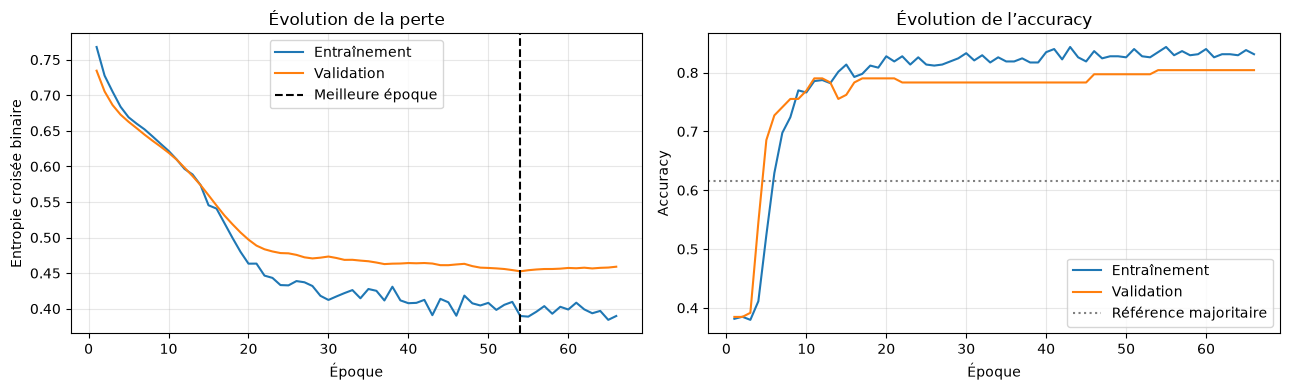

In [19]:
epoque = range(1, nombre_epoques + 1)

figure, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4),
)

axes[0].plot(
    epoque,
    historique_titanic.history["loss"],
    label="Entraînement",
)

axes[0].plot(
    epoque,
    historique_titanic.history["val_loss"],
    label="Validation",
)

axes[0].axvline(
    meilleure_epoque,
    color="black",
    linestyle="--",
    label="Meilleure époque",
)

axes[0].set_title("Évolution de la perte")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Entropie croisée binaire")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    epoque,
    historique_titanic.history["accuracy"],
    label="Entraînement",
)

axes[1].plot(
    epoque,
    historique_titanic.history["val_accuracy"],
    label="Validation",
)

axes[1].axhline(
    accuracy_reference,
    color="gray",
    linestyle=":",
    label="Référence majoritaire",
)

axes[1].set_title("Évolution de l’accuracy")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
resultats_validation = modele_titanic.evaluate(
    X_val_prepare,
    y_val_array,
    verbose=0,
    return_dict=True,
)

pd.Series(
    resultats_validation,
    name="Validation",
).round(3)

accuracy     0.804
auc          0.866
loss         0.453
precision    0.787
recall       0.673
Name: Validation, dtype: float64

In [21]:
print(
    f"Accuracy de référence : "
    f"{accuracy_reference:.3f}"
)

print(
    f"Accuracy du MLP : "
    f"{resultats_validation['accuracy']:.3f}"
)

Accuracy de référence : 0.615
Accuracy du MLP : 0.804


## Interprétation de l’entraînement

L’entraînement s’est arrêté après **66 époques**. La meilleure perte de
validation, égale à **0,4525**, a été obtenue à l’époque **54**.

Au début, les pertes d’entraînement et de validation diminuent : le
réseau apprend donc une relation utile dans les données.

Après l’époque 54, la perte de validation ne s’améliore plus et remonte
légèrement jusqu’à environ **0,4590**, tandis que la perte
d’entraînement reste autour de **0,39**. Cela indique un léger début de
surapprentissage.

L’arrêt anticipé a attendu 12 époques sans amélioration suffisante, puis
a arrêté l’entraînement à l’époque 66. Grâce à
`restore_best_weights=True`, les poids de l’époque 54 ont été restaurés.

L’accuracy de validation atteint **0,804**, contre **0,615** pour la
référence majoritaire.

Le Dropout est actif pendant l’entraînement mais désactivé pendant la
validation. Les deux pertes ne sont donc pas calculées dans des
conditions strictement identiques.

## Évaluation finale sur le jeu de test

Le modèle, le prétraitement et le seuil de décision ont été fixés sans
consulter le jeu de test.

Le seuil de classification est fixé à 0,5. Le jeu de test est maintenant
utilisé pour estimer une seule fois la capacité de généralisation du
modèle.

Les résultats du test ne serviront pas à modifier l’architecture.

In [22]:
probabilites_test = (
    modele_titanic.predict(
        X_test_prepare,
        verbose=0,
    )
    .ravel()
)

seuil_decision = 0.5

predictions_test = (
    probabilites_test >= seuil_decision
).astype(int)

print("Premières probabilités :")
print(np.round(probabilites_test[:10], 3))

print("\nPremières classes prédites :")
print(predictions_test[:10])

Premières probabilités :
[0.148 0.109 0.119 0.113 0.832 0.319 0.888 0.256 0.214 0.171]

Premières classes prédites :
[0 0 0 0 1 0 1 0 0 0]


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
)

y_test_entier = y_test_array.astype(int)

metriques_test = {
    "accuracy": accuracy_score(
        y_test_entier,
        predictions_test,
    ),
    "precision": precision_score(
        y_test_entier,
        predictions_test,
        zero_division=0,
    ),
    "recall": recall_score(
        y_test_entier,
        predictions_test,
        zero_division=0,
    ),
    "f1_score": f1_score(
        y_test_entier,
        predictions_test,
        zero_division=0,
    ),
    "auc": roc_auc_score(
        y_test_entier,
        probabilites_test,
    ),
}

pd.Series(
    metriques_test,
    name="Test",
).round(3)

accuracy     0.804
precision    0.870
recall       0.580
f1_score     0.696
auc          0.837
Name: Test, dtype: float64

In [24]:
print(
    classification_report(
        y_test_entier,
        predictions_test,
        target_names=[
            "Non-survivant",
            "Survivant",
        ],
        digits=3,
        zero_division=0,
    )
)

               precision    recall  f1-score   support

Non-survivant      0.782     0.945     0.856       110
    Survivant      0.870     0.580     0.696        69

     accuracy                          0.804       179
    macro avg      0.826     0.763     0.776       179
 weighted avg      0.816     0.804     0.794       179



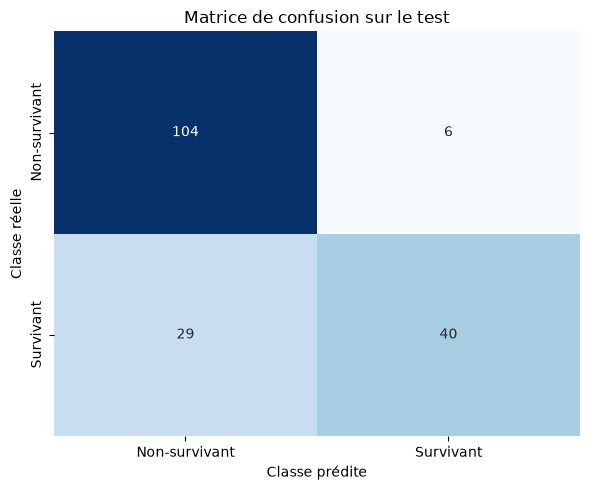

In [25]:
matrice = confusion_matrix(
    y_test_entier,
    predictions_test,
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    matrice,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=[
        "Non-survivant",
        "Survivant",
    ],
    yticklabels=[
        "Non-survivant",
        "Survivant",
    ],
)

plt.title("Matrice de confusion sur le test")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.tight_layout()
plt.show()

In [26]:
comparaison = pd.DataFrame(
    {
        "Validation": {
            "accuracy": resultats_validation["accuracy"],
            "precision": resultats_validation["precision"],
            "recall": resultats_validation["recall"],
            "auc": resultats_validation["auc"],
        },
        "Test": {
            "accuracy": metriques_test["accuracy"],
            "precision": metriques_test["precision"],
            "recall": metriques_test["recall"],
            "auc": metriques_test["auc"],
        },
    }
)

comparaison.round(3)

,Validation,Test
accuracy,0.804,0.804
precision,0.787,0.870
recall,0.673,0.580
auc,0.866,0.837


In [27]:
analyse_test = X_test.copy()

analyse_test["survie_reelle"] = (
    y_test_entier
)

analyse_test["probabilite_survie"] = (
    probabilites_test
)

analyse_test["classe_predite"] = (
    predictions_test
)

analyse_test["erreur"] = (
    analyse_test["survie_reelle"]
    != analyse_test["classe_predite"]
)

analyse_test["confiance"] = np.where(
    predictions_test == 1,
    probabilites_test,
    1 - probabilites_test,
)

erreurs_test = (
    analyse_test[analyse_test["erreur"]]
    .sort_values(
        "confiance",
        ascending=False,
    )
)

print("Nombre total d’erreurs :", len(erreurs_test))

erreurs_test.head(10)

Nombre total d’erreurs : 35


,pclass,sex,age,sibsp,parch,fare,embarked,survie_reelle,probabilite_survie,classe_predite,erreur,confiance
297,1,female,2.0,1,2,151.5500,S,0,0.985828,1,True,0.985828
199,2,female,24.0,0,0,13.0000,S,0,0.966131,1,True,0.966131
570,2,male,62.0,0,0,10.5000,S,1,0.083134,0,True,0.916866
271,3,male,25.0,0,0,0.0000,S,1,0.097188,0,True,0.902812
804,3,male,27.0,0,0,6.9750,S,1,0.103718,0,True,0.896282
146,3,male,27.0,0,0,7.7958,S,1,0.104524,0,True,0.895476
444,3,male,NaN,0,0,8.1125,S,1,0.104731,0,True,0.895269
455,3,male,29.0,0,0,7.8958,C,1,0.109812,0,True,0.890188
501,3,female,21.0,0,0,7.7500,Q,0,0.884417,1,True,0.884417
553,3,male,22.0,0,0,7.2250,C,1,0.119158,0,True,0.880842


In [28]:
faux_positifs = erreurs_test[
    (erreurs_test["survie_reelle"] == 0)
    & (erreurs_test["classe_predite"] == 1)
]

faux_negatifs = erreurs_test[
    (erreurs_test["survie_reelle"] == 1)
    & (erreurs_test["classe_predite"] == 0)
]

print("Faux positifs :", len(faux_positifs))
print("Faux négatifs :", len(faux_negatifs))

Faux positifs : 6
Faux négatifs : 29


In [29]:
faux_negatifs[
    [
        "pclass",
        "sex",
        "age",
        "fare",
        "embarked",
        "probabilite_survie",
        "confiance",
    ]
].head(10)

,pclass,sex,age,fare,embarked,probabilite_survie,confiance
570,2,male,62.0,10.5000,S,0.083134,0.916866
271,3,male,25.0,0.0000,S,0.097188,0.902812
804,3,male,27.0,6.9750,S,0.103718,0.896282
146,3,male,27.0,7.7958,S,0.104524,0.895476
444,3,male,NaN,8.1125,S,0.104731,0.895269
455,3,male,29.0,7.8958,C,0.109812,0.890188
553,3,male,22.0,7.2250,C,0.119158,0.880842
65,3,male,NaN,15.2458,C,0.135662,0.864338
17,2,male,NaN,13.0000,S,0.137003,0.862997
587,1,male,60.0,79.2000,C,0.160481,0.839519


In [34]:
tn, fp, fn, tp = matrice.ravel()

accuracy_reference_test = (
    y_test_entier == classe_majoritaire
).mean()

print("Vrais négatifs  :", tn)
print("Faux positifs   :", fp)
print("Faux négatifs   :", fn)
print("Vrais positifs  :", tp)
print(
    f"Référence majoritaire sur le test : "
    f"{accuracy_reference_test:.3f}"
)

Vrais négatifs  : 104
Faux positifs   : 6
Faux négatifs   : 29
Vrais positifs  : 40
Référence majoritaire sur le test : 0.615


## Conclusion de l’exercice tabulaire

Sur le jeu de test, le MLP obtient une accuracy de **0,804**, contre
**0,615** pour la référence majoritaire. Son AUC atteint **0,837**.

La précision de **0,870** signifie que 87,0 % des passagers prédits
survivants ont réellement survécu. Le rappel de **0,580** signifie que
le modèle retrouve 58,0 % des survivants réels.

La matrice de confusion contient **104 vrais négatifs**, **6 faux
positifs**, **29 faux négatifs** et **40 vrais positifs**. Le modèle
commet donc davantage de faux négatifs : il manque certains survivants.

Parmi les dix faux négatifs les plus confiants affichés, les dix sont
des hommes et sept voyagent en troisième classe, souvent avec un tarif
faible. Cette observation décrit seulement cet échantillon d’erreurs.
Elle ne démontre pas une relation causale.

L’accuracy du test est identique à celle de la validation (**0,804**).
L’AUC diminue légèrement de **0,866** à **0,837**. La précision augmente
de **0,787** à **0,870**, mais le rappel diminue de **0,673** à
**0,580**.

La généralisation reste globalement cohérente, mais le modèle est plus
conservateur sur le test : lorsqu’il prédit une survie, il se trompe
rarement, mais il manque davantage de survivants.

Ces résultats restent limités par la petite taille du jeu de données,
les valeurs manquantes, le seuil de décision fixé à 0,5 et les
informations disponibles sur chaque passager.

# Comprendre mathématiquement le MLP Titanic

L’architecture utilisée est :

$$
12 \longrightarrow 16 \longrightarrow 8 \longrightarrow 1
$$

Le réseau apprend une fonction :

$$
f_\theta:\mathbb{R}^{12}\rightarrow[0,1]
$$

où :

- $x\in\mathbb{R}^{12}$ représente un passager prétraité ;
- $\theta$ représente tous les poids et biais du réseau ;
- $f_\theta(x)$ est le score de survie produit par le modèle.

Le modèle contient deux couches cachées utilisant ReLU, une couche
Dropout et un neurone de sortie utilisant une sigmoïde.

## 1. Construction du vecteur d’entrée

Les quatre variables numériques sont :

$$
\text{age},\quad \text{sibsp},\quad \text{parch},\quad \text{fare}
$$

Les variables catégorielles produisent :

- trois colonnes pour `pclass` ;
- deux colonnes pour `sex` ;
- trois colonnes pour `embarked`.

Le nombre total d’entrées est donc :

$$
4+3+2+3=12
$$

Un passager devient un vecteur :

$$
x=(x_1,x_2,\ldots,x_{12})\in\mathbb{R}^{12}
$$

### Imputation

Lorsqu’une valeur numérique est absente, elle est remplacée par la
médiane calculée sur l’entraînement :

$$
x^*_{ij}=
\begin{cases}
x_{ij} & \text{si la valeur est connue}\\
\operatorname{médiane}(X_{\text{train},j}) & \text{sinon}
\end{cases}
$$

Pour une variable catégorielle, la modalité la plus fréquente de
l’entraînement est utilisée.

### Standardisation

Pour chaque variable numérique $j$, le préprocesseur calcule :

$$
\mu_j=\frac{1}{n}\sum_{i=1}^{n}x^*_{ij}
$$

et :

$$
\sigma_j=
\sqrt{
\frac{1}{n}
\sum_{i=1}^{n}(x^*_{ij}-\mu_j)^2
}
$$

La valeur transmise au réseau est :

$$
x'_{ij}=\frac{x^*_{ij}-\mu_j}{\sigma_j}
$$

Une valeur standardisée proche de zéro est proche de la moyenne. Une
valeur positive est supérieure à la moyenne et une valeur négative est
inférieure à la moyenne.

Les médianes, les moyennes et les écarts-types sont calculés uniquement
sur l’ensemble d’entraînement afin d’éviter une fuite de données.

### Encodage one-hot

Une catégorie devient un vecteur binaire. Par exemple :

$$
\text{pclass}=2
\quad\longrightarrow\quad
(0,1,0)
$$

Cet encodage évite d’imposer une distance numérique artificielle entre
les catégories.

## 2. Calcul effectué par un neurone

Un neurone reçoit $d$ entrées et calcule une combinaison affine :

$$
z=w_1x_1+w_2x_2+\cdots+w_dx_d+b
$$

Sous forme vectorielle :

$$
z=w^\top x+b
$$

où :

- $w_i$ est le poids associé à l’entrée $x_i$ ;
- $b$ est le biais ;
- $z$ est le score avant activation.

Le neurone applique ensuite une fonction d’activation :

$$
a=f(z)
$$

Les poids déterminent comment les entrées sont combinées. Le biais
permet de déplacer le seuil d’activation. Les poids et les biais sont
appris pendant l’entraînement.

## 3. Première couche dense

Pour un mini-lot contenant $B$ passagers :

$$
X\in\mathbb{R}^{B\times12}
$$

La première couche possède une matrice de poids :

$$
W_1\in\mathbb{R}^{12\times16}
$$

et un vecteur de biais :

$$
b_1\in\mathbb{R}^{16}
$$

Elle calcule :

$$
Z_1=XW_1+b_1
$$

Le résultat contient 16 valeurs par passager :

$$
Z_1\in\mathbb{R}^{B\times16}
$$

Pour le passager $i$ et le neurone $j$ :

$$
z^{(1)}_{ij}
=
\sum_{k=1}^{12}
x_{ik}W^{(1)}_{kj}
+b^{(1)}_j
$$

La fonction ReLU est ensuite appliquée :

$$
H_1=\operatorname{ReLU}(Z_1)
$$

avec :

$$
\operatorname{ReLU}(z)=\max(0,z)
$$

Donc :

$$
\operatorname{ReLU}(z)=
\begin{cases}
z & \text{si }z>0\\
0 & \text{si }z\leq0
\end{cases}
$$

Sans fonction d’activation non linéaire, plusieurs couches denses
successives resteraient équivalentes à une seule transformation affine.
ReLU permet donc au réseau d’apprendre des interactions non linéaires
entre les caractéristiques.

## 4. Dropout et deuxième couche

Le Dropout utilise un taux de suppression de 20 %. La probabilité de
conserver une activation est donc :

$$
q=1-0{,}20=0{,}80
$$

Pendant l’entraînement, un masque aléatoire est tiré :

$$
M_{ij}\sim\operatorname{Bernoulli}(0{,}8)
$$

La sortie du Dropout est :

$$
\widetilde H_1=
\frac{M\odot H_1}{0{,}8}
$$

Une activation supprimée devient zéro. Une activation conservée est
multipliée par $1/0{,}8=1{,}25$.

Cette correction conserve la valeur moyenne :

$$
\mathbb{E}[\widetilde H_1\mid H_1]=H_1
$$

Pendant la validation, le test et les prédictions, le Dropout est
désactivé :

$$
\widetilde H_1=H_1
$$

La deuxième couche possède :

$$
W_2\in\mathbb{R}^{16\times8}
$$

et :

$$
b_2\in\mathbb{R}^{8}
$$

Elle calcule :

$$
Z_2=\widetilde H_1W_2+b_2
$$

puis :

$$
H_2=\operatorname{ReLU}(Z_2)
$$

## 5. Sortie sigmoïde

La dernière couche possède :

$$
W_3\in\mathbb{R}^{8\times1}
$$

et un biais scalaire $b_3$.

Elle calcule le logit :

$$
Z_3=H_2W_3+b_3
$$

La sigmoïde transforme ce logit en score compris entre zéro et un :

$$
p=\sigma(Z_3)=\frac{1}{1+e^{-Z_3}}
$$

Avec un seuil de $0{,}5$ :

$$
\widehat y=
\begin{cases}
1 & \text{si }p\geq0{,}5\\
0 & \text{sinon}
\end{cases}
$$

Comme $\sigma(0)=0{,}5$, cela revient à prédire la survie lorsque le
logit est positif ou nul.

## 6. Nombre de paramètres

Pour une couche dense possédant $d$ entrées et $h$ neurones :

$$
\text{paramètres}=d\times h+h
$$

Première couche :

$$
12\times16+16=208
$$

Deuxième couche :

$$
16\times8+8=136
$$

Couche de sortie :

$$
8\times1+1=9
$$

Le nombre total de paramètres entraînables est :

$$
208+136+9=353
$$

ReLU, la sigmoïde et le Dropout ne possèdent aucun paramètre
entraînable.

In [30]:
couches_denses = [
    couche
    for couche in modele_titanic.layers
    if isinstance(
        couche,
        tf.keras.layers.Dense,
    )
]

for numero, couche in enumerate(
    couches_denses,
    start=1,
):
    poids, biais = couche.get_weights()

    print(
        f"Couche dense {numero} : "
        f"poids {poids.shape}, "
        f"biais {biais.shape}"
    )

print(
    "\nNombre total de paramètres :",
    modele_titanic.count_params(),
)

Couche dense 1 : poids (12, 16), biais (16,)
Couche dense 2 : poids (16, 8), biais (8,)
Couche dense 3 : poids (8, 1), biais (1,)

Nombre total de paramètres : 353


# Perte et rétropropagation

## 7. Entropie croisée binaire

Pour une observation, la vraie cible est :

$$
y\in\{0,1\}
$$

et le réseau produit une probabilité :

$$
p\in]0,1[
$$

La fonction de perte utilisée est l’entropie croisée binaire :

$$
\ell(y,p)
=
-\left[
y\ln(p)+(1-y)\ln(1-p)
\right]
$$

### Cas d’un survivant

Si $y=1$, la formule devient :

$$
\ell(1,p)=-\ln(p)
$$

Une probabilité élevée produit une petite perte :

$$
-\ln(0{,}9)\approx0{,}105
$$

Une probabilité faible produit une forte perte :

$$
-\ln(0{,}1)\approx2{,}303
$$

### Cas d’un non-survivant

Si $y=0$, la formule devient :

$$
\ell(0,p)=-\ln(1-p)
$$

Ainsi :

$$
-\ln(1-0{,}1)\approx0{,}105
$$

mais :

$$
-\ln(1-0{,}9)\approx2{,}303
$$

Une prédiction fausse et très confiante reçoit donc une forte pénalité.

Une prédiction incertaine $p=0{,}5$ produit :

$$
-\ln(0{,}5)\approx0{,}693
$$

In [31]:
def bce_manuelle(y, p):
    epsilon = 1e-7

    p = np.clip(
        p,
        epsilon,
        1 - epsilon,
    )

    return -(
        y * np.log(p)
        + (1 - y) * np.log(1 - p)
    )


exemples_bce = pd.DataFrame(
    [
        {
            "cible": 1,
            "probabilite": 0.90,
        },
        {
            "cible": 1,
            "probabilite": 0.50,
        },
        {
            "cible": 1,
            "probabilite": 0.10,
        },
        {
            "cible": 0,
            "probabilite": 0.10,
        },
        {
            "cible": 0,
            "probabilite": 0.90,
        },
    ]
)

exemples_bce["perte"] = [
    bce_manuelle(y, p)
    for y, p in zip(
        exemples_bce["cible"],
        exemples_bce["probabilite"],
    )
]

exemples_bce.round(3)

,cible,probabilite,perte
0,1,0.9,0.105
1,1,0.5,0.693
2,1,0.1,2.303
3,0,0.1,0.105
4,0,0.9,2.303


## 8. Perte moyenne d’un mini-lot

Pour un mini-lot contenant $B$ passagers, le modèle minimise la perte
moyenne :

$$
J(\theta)
=
\frac{1}{B}
\sum_{i=1}^{B}
\ell(y_i,p_i)
$$

Le symbole $\theta$ représente tous les paramètres du réseau :

$$
\theta=
\{
W_1,b_1,
W_2,b_2,
W_3,b_3
\}
$$

### Interprétation probabiliste

La cible est modélisée par une loi de Bernoulli :

$$
P(Y=y\mid x)
=
p^y(1-p)^{1-y}
$$

Son logarithme est :

$$
\ln P(Y=y\mid x)
=
y\ln(p)+(1-y)\ln(1-p)
$$

Maximiser la vraisemblance des observations revient à minimiser son
opposé :

$$
-\ln P(Y=y\mid x)
=
-\left[
y\ln(p)+(1-y)\ln(1-p)
\right]
$$

Cette expression est exactement l’entropie croisée binaire.

### Pourquoi ne pas minimiser directement l’accuracy ?

L’accuracy utilise la décision :

$$
\mathbf{1}[p\geq0{,}5]
$$

Cette fonction est discontinue et ne fournit pas de gradient utile.

La BCE est continue et différentiable. Elle tient également compte de la
confiance du modèle. Deux modèles peuvent donc avoir la même accuracy
mais des pertes différentes.

## 9. Dérivée du couple sigmoïde et BCE

La sigmoïde est :

$$
p=\sigma(z)=\frac{1}{1+e^{-z}}
$$

Sa dérivée vaut :

$$
\frac{\partial p}{\partial z}
=
p(1-p)
$$

La dérivée de la BCE par rapport à $p$ est :

$$
\frac{\partial\ell}{\partial p}
=
-\frac{y}{p}
+
\frac{1-y}{1-p}
$$

En mettant les termes au même dénominateur :

$$
\frac{\partial\ell}{\partial p}
=
\frac{p-y}{p(1-p)}
$$

La règle de dérivation en chaîne donne :

$$
\frac{\partial\ell}{\partial z}
=
\frac{\partial\ell}{\partial p}
\frac{\partial p}{\partial z}
$$

Donc :

$$
\frac{\partial\ell}{\partial z}
=
\frac{p-y}{p(1-p)}
\times p(1-p)
$$

Les deux termes se simplifient :

$$
\boxed{
\frac{\partial\ell}{\partial z}=p-y
}
$$

C’est le résultat fondamental du couple sigmoïde et entropie croisée
binaire.

Si $y=1$ et que $p$ est trop faible, $p-y$ est négatif : la mise à jour
doit augmenter le logit.

Si $y=0$ et que $p$ est trop élevé, $p-y$ est positif : la mise à jour
doit diminuer le logit.

In [32]:
z_exemple = tf.Variable(
    [[0.7]],
    dtype=tf.float32,
)

y_exemple = tf.constant(
    [[1.0]],
    dtype=tf.float32,
)

fonction_bce = (
    tf.keras.losses.BinaryCrossentropy()
)

with tf.GradientTape() as ruban:
    p_exemple = tf.math.sigmoid(
        z_exemple
    )

    perte_exemple = fonction_bce(
        y_exemple,
        p_exemple,
    )

gradient_automatique = ruban.gradient(
    perte_exemple,
    z_exemple,
)

gradient_theorique = (
    p_exemple - y_exemple
)

print(
    "Probabilité :",
    p_exemple.numpy().ravel()[0],
)

print(
    "Gradient TensorFlow :",
    gradient_automatique.numpy().ravel()[0],
)

print(
    "Valeur de p - y :",
    gradient_theorique.numpy().ravel()[0],
)

assert np.allclose(
    gradient_automatique.numpy(),
    gradient_theorique.numpy(),
    atol=1e-6,
)

Probabilité : 0.6681878
Gradient TensorFlow : -0.3318122
Valeur de p - y : -0.3318122


## 10. Rétropropagation dans la couche de sortie

Pour un mini-lot, les prédictions et les cibles ont la forme :

$$
P,Y\in\mathbb{R}^{B\times1}
$$

On incorpore la moyenne sur le mini-lot dans :

$$
D_3=\frac{P-Y}{B}
$$

avec :

$$
D_3\in\mathbb{R}^{B\times1}
$$

Le gradient de la dernière matrice de poids est :

$$
\nabla_{W_3}J
=
H_2^\top D_3
$$

Vérification des dimensions :

$$
(B\times8)^\top(B\times1)
=
(8\times B)(B\times1)
=
8\times1
$$

Le gradient du biais est :

$$
\nabla_{b_3}J
=
\sum_{i=1}^{B}D_{3,i}
$$

### Retour dans la deuxième couche

L’erreur est propagée vers la couche précédente :

$$
D_2
=
(D_3W_3^\top)
\odot
\mathbf{1}_{Z_2>0}
$$

Le symbole $\odot$ représente une multiplication terme par terme.

Le terme :

$$
\mathbf{1}_{Z_2>0}
$$

correspond à la dérivée de ReLU :

$$
\operatorname{ReLU}'(z)=
\begin{cases}
1 & \text{si }z>0\\
0 & \text{si }z\leq0
\end{cases}
$$

Les gradients de la deuxième couche sont :

$$
\nabla_{W_2}J
=
\widetilde H_1^\top D_2
$$

et :

$$
\nabla_{b_2}J
=
\sum_{i=1}^{B}D_{2,i,:}
$$

## 11. Rétropropagation à travers le Dropout

L’erreur arrivant à la sortie du Dropout est :

$$
D_{\widetilde H_1}
=
D_2W_2^\top
$$

Elle traverse ensuite le même masque que celui utilisé pendant la
propagation avant :

$$
D_{H_1}
=
D_{\widetilde H_1}
\odot
\frac{M}{0{,}8}
$$

Un neurone supprimé par le Dropout reçoit un gradient nul pendant ce
passage. Un neurone conservé transmet un gradient multiplié par
$1/0{,}8=1{,}25$.

### Retour dans la première couche

La dérivée de ReLU est appliquée :

$$
D_1
=
D_{H_1}
\odot
\mathbf{1}_{Z_1>0}
$$

Les gradients sont ensuite :

$$
\nabla_{W_1}J
=
X^\top D_1
$$

et :

$$
\nabla_{b_1}J
=
\sum_{i=1}^{B}D_{1,i,:}
$$

La rétropropagation applique donc la règle de dérivation en chaîne depuis
la sortie jusqu’à la première couche.

Elle calcule les gradients, mais elle ne modifie pas directement les
poids. La modification des paramètres sera effectuée par l’optimiseur
Adam.

## 12. Résumé de la rétropropagation

La propagation avant calcule :

$$
X
\rightarrow
Z_1
\rightarrow
H_1
\rightarrow
\widetilde H_1
\rightarrow
Z_2
\rightarrow
H_2
\rightarrow
Z_3
\rightarrow
P
\rightarrow
J
$$

La rétropropagation parcourt le chemin inverse :

$$
J
\rightarrow
D_3
\rightarrow
D_2
\rightarrow
D_1
\rightarrow
\nabla W_3,\nabla W_2,\nabla W_1
$$

TensorFlow réalise ces calculs automatiquement grâce à la
différentiation automatique.

Pour chaque paramètre, le gradient indique dans quelle direction une
petite variation ferait augmenter la perte. L’optimiseur déplace ensuite
le paramètre dans la direction opposée.

In [33]:
X_lot = tf.convert_to_tensor(
    X_train_prepare[:32],
    dtype=tf.float32,
)

y_lot = tf.reshape(
    tf.convert_to_tensor(
        y_train_array[:32],
        dtype=tf.float32,
    ),
    shape=(-1, 1),
)

fonction_perte = (
    tf.keras.losses.BinaryCrossentropy()
)

tf.random.set_seed(SEED)

with tf.GradientTape() as ruban:
    probabilites_lot = modele_titanic(
        X_lot,
        training=True,
    )

    perte_lot = fonction_perte(
        y_lot,
        probabilites_lot,
    )

gradients = ruban.gradient(
    perte_lot,
    modele_titanic.trainable_variables,
)

print(
    f"Perte du mini-lot : "
    f"{float(perte_lot):.4f}\n"
)

for variable, gradient in zip(
    modele_titanic.trainable_variables,
    gradients,
):
    nom = getattr(
        variable,
        "path",
        variable.name,
    )

    print(
        f"{nom:50s} "
        f"paramètre={tuple(variable.shape)} "
        f"gradient={tuple(gradient.shape)}"
    )

Perte du mini-lot : 0.2323

mlp_titanic/couche_dense_1/kernel                  paramètre=(12, 16) gradient=(12, 16)
mlp_titanic/couche_dense_1/bias                    paramètre=(16,) gradient=(16,)
mlp_titanic/couche_dense_2/kernel                  paramètre=(16, 8) gradient=(16, 8)
mlp_titanic/couche_dense_2/bias                    paramètre=(8,) gradient=(8,)
mlp_titanic/probabilite_survie/kernel              paramètre=(8, 1) gradient=(8, 1)
mlp_titanic/probabilite_survie/bias                paramètre=(1,) gradient=(1,)


# Optimisation du MLP

## 13. Rétropropagation et optimiseur : deux rôles différents

La rétropropagation et Adam n’effectuent pas la même opération.

Pour un mini-lot, la rétropropagation utilise la règle de dérivation en
chaîne afin de calculer le gradient de la perte par rapport à tous les
paramètres :

\[
g_t
=
\nabla_{\theta}J_t(\theta_{t-1})
\]

Le gradient indique comment une petite modification d’un paramètre
influencerait la perte.

La rétropropagation répond donc à la question :

> Dans quelle direction chaque paramètre influence-t-il l’erreur ?

Adam reçoit ensuite ces gradients et répond à une autre question :

> De combien faut-il modifier chaque paramètre à cette étape ?

La fonction de perte reste l’entropie croisée binaire. Adam ne remplace
pas cette perte : il utilise ses gradients pour modifier les poids et
les biais.

## 14. Formules de l’optimiseur Adam

Pour chaque paramètre, Adam mémorise une moyenne mobile des gradients :

\[
m_t
=
\beta_1m_{t-1}
+
(1-\beta_1)g_t
\]

\(m_t\) représente la direction moyenne récente des gradients. Cette
mémoire donne une forme d’inertie à l’apprentissage.

Adam mémorise également une moyenne mobile des gradients au carré :

\[
v_t
=
\beta_2v_{t-1}
+
(1-\beta_2)g_t^2
\]

\(v_t\) représente l’échelle récente des gradients. Un paramètre ayant
des gradients très grands reçoit ainsi une mise à jour davantage
normalisée.

Comme \(m_0\) et \(v_0\) commencent à zéro, Keras corrige leur biais
initial en calculant un taux d’apprentissage adapté à l’étape \(t\) :

\[
\alpha_t
=
\alpha
\frac{\sqrt{1-\beta_2^t}}
{1-\beta_1^t}
\]

La mise à jour réellement utilisée par la version de Keras installée
s’écrit :

\[
\theta_t
=
\theta_{t-1}
-
\frac{\alpha_t m_t}
{\sqrt{v_t}+\varepsilon}
\]

Dans notre modèle :

\[
\alpha=0{,}001,\qquad
\beta_1=0{,}9,\qquad
\beta_2=0{,}999,\qquad
\varepsilon=10^{-7}
\]

- \(\alpha\) est le taux d’apprentissage de base ;
- \(\beta_1\) contrôle la mémoire de la direction des gradients ;
- \(\beta_2\) contrôle la mémoire de leur amplitude ;
- \(\varepsilon\) évite une division par zéro ;
- \(t\) compte les mises à jour, donc les mini-lots, et non les époques.

Les carrés, racines et divisions sont effectués élément par élément.

Si un gradient reste positif pendant plusieurs mini-lots, \(m_t\)
devient positif. Comme Adam soustrait la mise à jour, le paramètre
concerné diminue.

Inversement, si un paramètre possède des gradients de grande amplitude,
\(v_t\) augmente et le dénominateur limite la taille de ses mises à jour.

Avec `amsgrad=False`, Keras utilise la version standard d’Adam, sans la
variante AMSGrad.

In [35]:
configuration_adam = (
    modele_titanic.optimizer.get_config()
)

parametres_adam = [
    "learning_rate",
    "beta_1",
    "beta_2",
    "epsilon",
    "amsgrad",
]

pd.Series(
    {
        parametre: configuration_adam[parametre]
        for parametre in parametres_adam
    },
    name="Configuration Adam",
)

learning_rate    0.001
beta_1             0.9
beta_2           0.999
epsilon            0.0
amsgrad          False
Name: Configuration Adam, dtype: object